# LABS-12: Value

In this lab we will explore and observe how a model performs over different classes using our kNN model that we built in the Analytics lab. We will be using the Fairlearn package to calculate various metrics to help us understand how our model performs across different classes.

Check out their [user guide](https://fairlearn.org/v0.10/user_guide/fairness_in_machine_learning.html) for more information on the package!

## Continuity with Lab 10
The starter calls Analytics Lab 9; this course used Lab 10. We retain its cutoff (>65 high), k=21, split seed 45 and training-only MinMax scaling. The cleaned CSV stores unscaled values. Country codes are interpreted as dataset labels, not verified production origins. True in each binary comparison means the named most prevalent class; False pools all remaining classes.

If you are working through collab, be sure to run this pip install cell!

In [1]:
# Install once in your active environment: python -m pip install fairlearn
import fairlearn
print("Fairlearn version:", fairlearn.__version__)

Fairlearn version: 0.15.0


In [2]:
# import packages

import pandas as pd #data ingestion & cleaning
import numpy as np #numbers

# modeling
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

# Fairness metrics
import fairlearn.metrics
from fairlearn.metrics import MetricFrame
from fairlearn.metrics import count, true_positive_rate, false_positive_rate, selection_rate, demographic_parity_ratio

# visualization
import matplotlib.pyplot as plt

## Recreate the model
First you will rebuild the model that you made in LABS-9: Analytics.

### Read in the data
The data you are reading in is the **cleaned** data that you created in LABS-9. Upload it to folders in collab if your using it.

In [3]:
## read in cleaned data
model_data = pd.read_csv("imdb_movies_cleaned.csv")

For the FairLearn package, the target variable must be coded as 0/1.

In [4]:
# Recode 'score' as 0 (low) or 1 (high)
model_data['score'] = model_data['score'].map({'low': 0, 'high': 1})

### Seperate features from target

In [5]:
# features: all columns except 'score'
features = model_data.drop('score', axis=1)

# Target: score column
target = model_data['score']

### Dummy variables

In [6]:
## create dummy variables for the features dataframe
features = pd.get_dummies(features)

# preview the new features dataframe
features.head()

,budget_x,revenue,year,country_AU,country_ES,country_FR,country_GB,country_HK,country_IT,country_JP,...,top_lang_ Norwegian,top_lang_ Polish,top_lang_ Portuguese,top_lang_ Russian,top_lang_ Spanish,top_lang_ Swedish,top_lang_ Tagalog,top_lang_ Thai,top_lang_ Turkish,top_lang_other
0,75000000.0,2.716167e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,460000000.0,2.316795e+09,2022,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,100000000.0,7.244590e+08,2023,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,12300000.0,3.420000e+07,2023,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,77000000.0,3.409420e+08,2023,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


### Train/Test split

In [7]:
# train test split
features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.2, random_state=45)

# Match Lab 10: learn scaling only from training rows.
from sklearn.preprocessing import MinMaxScaler
numeric_cols = ['budget_x', 'revenue', 'year']
scaler = MinMaxScaler()
features_train = features_train.copy()
features_test = features_test.copy()
features_train[numeric_cols] = scaler.fit_transform(features_train[numeric_cols])
features_test[numeric_cols] = scaler.transform(features_test[numeric_cols])


### Model: Build, Train, Test, and Evaluate

In the cell below, insert the k value you chose in LABS-9: Analtics for `n_neighbors` before running it.

In [8]:
# Create the model
knn = KNeighborsClassifier(n_neighbors=21)  # insert the k value you chose in LABS-9 here!

# Train the model
knn.fit(features_train, target_train)

# Test the model
target_predicted = knn.predict(features_test)

# Evaluate the model
print("Accuracy:", accuracy_score(target_test, target_predicted))

Accuracy: 0.7140726006961711


In [9]:
## Print out the data to use below
model_data.head()

,score,budget_x,revenue,country,top_genre,top_lang,year
0,1,75000000.0,2.716167e+08,AU,Drama,English,2023
1,1,460000000.0,2.316795e+09,AU,Science Fiction,English,2022
2,1,100000000.0,7.244590e+08,AU,Animation,English,2023
3,1,12300000.0,3.420000e+07,AU,Animation,Spanish,2023
4,0,77000000.0,3.409420e+08,US,Action,English,2023


## Look at the Data for each category

Type the name of the category you'd like to explore in the quotes below. Be sure to use the exact name (case sensitive!) of the column from the data frame above.

> Use this information to answer **question 2**.

country 
 country
AU       4880
US       2716
other     709
JP        502
KR        358
FR        219
GB        172
ES        151
IT        123
HK        120
MX        102


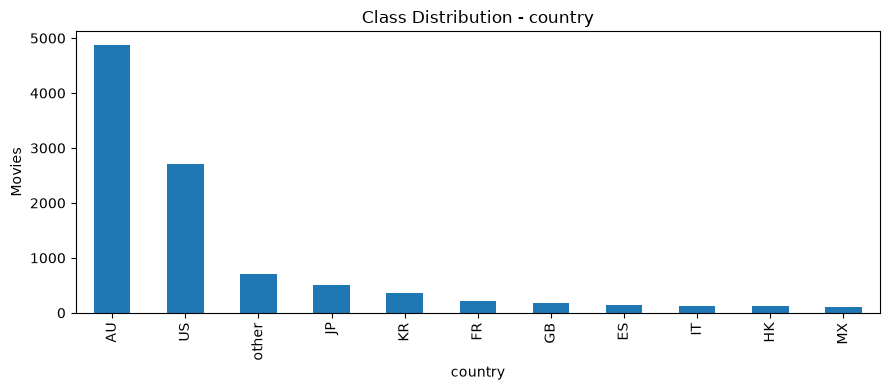

top_genre 
 top_genre
Drama              1865
Action             1563
Comedy             1377
Horror              931
Animation           885
Thriller            577
Adventure           571
Romance             413
Crime               371
Family              333
Science Fiction     313
Fantasy             263
Documentary         176
Mystery             108
War                  77
Music                76
Western              72
History              46
TV Movie             35


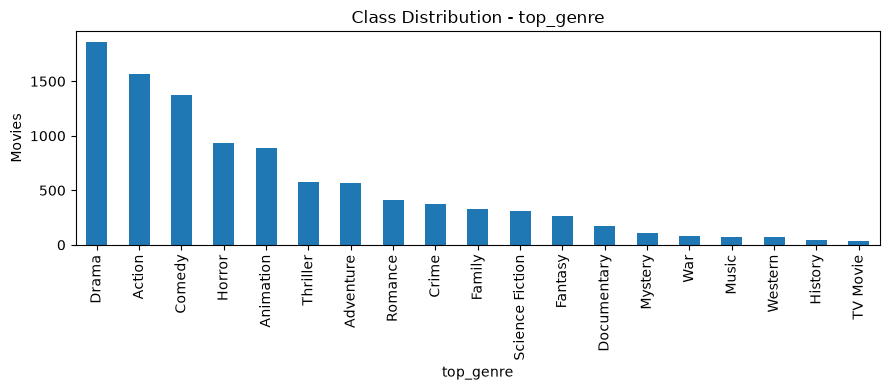

top_lang 
 top_lang
 English       7381
 Japanese       675
 Spanish        388
 Korean         384
 French         282
 Chinese        144
 Italian        142
 Cantonese      141
 German          89
other            72
 Russian         65
 Tagalog         42
 Portuguese      35
 Thai            33
 Norwegian       29
 Polish          26
 Hindi           26
 Danish          23
 Swedish         22
 Dutch           21
 Turkish         21
 Indonesian      11


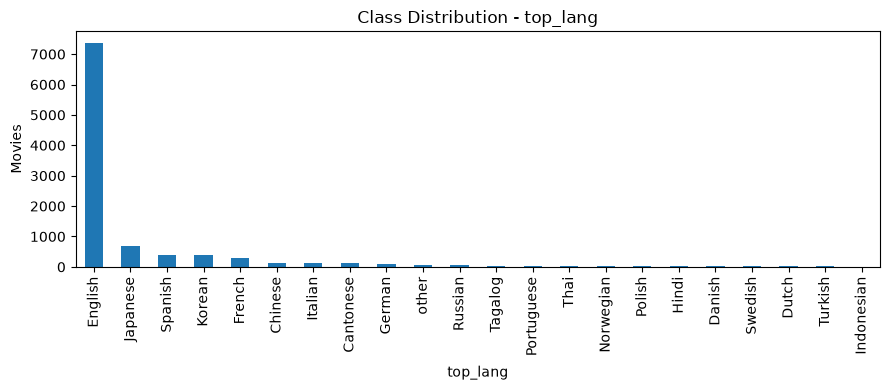

In [10]:
from pathlib import Path
Path('figures').mkdir(exist_ok=True)
for category in ['country', 'top_genre', 'top_lang']:
    counts = model_data[category].value_counts()
    print(category, '\n', counts.to_string())
    counts.rename('count').to_csv(f'{category}_representation.csv')
    fig, ax = plt.subplots(figsize=(9, 4))
    counts.plot.bar(ax=ax)
    ax.set(ylabel='Movies', xlabel=category, title=f'Class Distribution - {category}')
    fig.tight_layout()
    fig.savefig(f'figures/{category}_representation.png', dpi=180)
    plt.show()


## Fairness Metrics

We are using the Fairlearn package in Python.

You will need to understand what the metrics used below mean and how they are calculated. You can find information on the functions used in their documentation: https://fairlearn.org/v0.10/api_reference/index.html#module-fairlearn.metrics

In [11]:
# Construct a function dictionary with the metrics we'd like for each category
my_metrics = {
    'true positive rate' : true_positive_rate,
    'false positive rate' : false_positive_rate,
    'selection rate' : selection_rate,
    'count' : count
}
# Construct a MetricFrame for country
mf_country = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["country_AU"]
)

# Construct a MetricFrame for top_lang
mf_lang = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["top_lang_ English"]
)

# Construct a MetricFrame for top_genre
mf_genre = MetricFrame(
    metrics=my_metrics,
    y_true=target_test,
    y_pred=target_predicted,
    sensitive_features=features_test["top_genre_Drama"]
)

In [12]:
def create_confmatrix(target_test, target_predicted):
    '''
    creates a confusion matrix with more descriptive formatting
    '''
    tn, fp, fn, tp = confusion_matrix(target_test, target_predicted).ravel() # grab the individual values

    # create a data frame with the values in the correct spots
    conf_matrix = pd.DataFrame({'predicted positive': [tp, fp],
                                'predicted negative': [fn, tn]},
                                index=['actual positive','actual negative'])

    # return the dataframe to be saved/viewed
    return conf_matrix

### Overall metrics

Here is the confusion matrix for the model overall with *counts* for the true positive, false positive, true negative, and false negative.

For more information on confusion matrices, check out the wiki page: https://en.wikipedia.org/wiki/Confusion_matrix

> Use this information to answer **quesiton 4**.

In [13]:
# overall confusion matrix
print("Confusion matrix for all test data:")
create_confmatrix(target_test, target_predicted)

Confusion matrix for all test data:


,predicted positive,predicted negative
actual positive,684,304
actual negative,271,752


In [14]:
## The overall metrics. You'll use these to compare to with the metrics broken down by each category below.
## Think about how the differing performance would impact that group based on your understanding of each metric.
pd.DataFrame(mf_country.overall, columns = ["overall"]).T

,true positive rate,false positive rate,selection rate,count
overall,0.692308,0.264907,0.474888,2011.0


### Metrics by category

Here we are comparing the most prevalent class in each category to the rest of the categories.

> Use this information to answer **questions 5 & 6**.

#### `country`

The most prevalent country value is "AU". We will compare the model performance for the most prevalent country to the performance on the rest of the countries.

In [15]:
## metrics broken down by country classes. Compare these to the metrics above.
mf_country.by_group

,true positive rate,false positive rate,selection rate,count
country_AU,,,,
False,0.620137,0.209059,0.386746,1011.0
True,0.749546,0.336303,0.564000,1000.0


In [16]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_country = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["country_AU"])
print("Demographic Parity ratio:\t", dpr_country)

eodds_country = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["country_AU"])
print("Equalized Odds ratio:\t\t", eodds_country)

Demographic Parity ratio:	 0.6857194968818178
Equalized Odds ratio:		 0.621639707409373


#### `top_lang`


The most prevalent language value is "English". We will compare the model performance for the most prevalent language to the performance on the rest of the languages.

In [17]:
## metrics broken down by top_lang classes. Compare these to the metrics above.

mf_lang.by_group

,true positive rate,false positive rate,selection rate,count
top_lang_ English,,,,
False,0.728814,0.323529,0.547842,533.0
True,0.676768,0.247134,0.448579,1478.0


In [18]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_lang = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["top_lang_ English"])
print("Demographic Parity ratio:\t", dpr_lang)

eodds_lang = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["top_lang_ English"])
print("Equalized Odds ratio:\t\t", eodds_lang)

Demographic Parity ratio:	 0.8188105918772128
Equalized Odds ratio:		 0.7638679791546034


#### `top_genre`


The most prevalent genre value is "Drama". We will compare the model performance for the most prevalent genre to the performance on the rest of the genres.

In [19]:
## metrics broken down by top_genre classes. Compare these to the metrics above.

mf_genre.by_group

,true positive rate,false positive rate,selection rate,count
top_genre_Drama,,,,
False,0.649194,0.230425,0.420635,1638.0
True,0.823770,0.503876,0.713137,373.0


In [20]:
# Derived fairness metrics. Be sure you understand the scale and meaning of these.

dpr_genre = fairlearn.metrics.demographic_parity_ratio(target_test, target_predicted, sensitive_features=features_test["top_genre_Drama"])
print("Demographic Parity ratio:\t", dpr_genre)

eodds_genre = fairlearn.metrics.equalized_odds_ratio(target_test, target_predicted, sensitive_features=features_test["top_genre_Drama"])
print("Equalized Odds ratio:\t\t", eodds_genre)

Demographic Parity ratio:	 0.5898376894617496


Equalized Odds ratio:		 0.45730511099638615


In [21]:
import json
from sklearn.metrics import confusion_matrix
results = {'accuracy': float(accuracy_score(target_test,target_predicted)),
           'confusion_matrix_tn_fp_fn_tp': confusion_matrix(target_test,target_predicted,labels=[0,1]).ravel().tolist(),
           'overall': {k:float(v) for k,v in mf_country.overall.items()}, 'groups':{}, 'representation':{}}
for name, mf, indicator in [('country',mf_country,'country_AU'),('top_lang',mf_lang,'top_lang_ English'),('top_genre',mf_genre,'top_genre_Drama')]:
    frame = mf.by_group.copy()
    sensitive = features_test[indicator]
    rows=[]
    for group in [False,True]:
        mask = sensitive == group
        tn,fp,fn,tp=confusion_matrix(target_test[mask],target_predicted[mask],labels=[0,1]).ravel()
        row={'group':bool(group), **{k:float(v) for k,v in frame.loc[group].items()},'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
        assert abs(row['true positive rate']-tp/(tp+fn)) < 1e-12
        assert abs(row['false positive rate']-fp/(fp+tn)) < 1e-12
        rows.append(row)
    dpr=fairlearn.metrics.demographic_parity_ratio(target_test,target_predicted,sensitive_features=sensitive)
    eor=fairlearn.metrics.equalized_odds_ratio(target_test,target_predicted,sensitive_features=sensitive)
    expected=min(min(r[m] for r in rows)/max(r[m] for r in rows) for m in ['true positive rate','false positive rate'])
    assert abs(eor-expected)<1e-12
    results['groups'][name]={'rows':rows,'DPR':float(dpr),'EOR':float(eor)}
    results['representation'][name]={str(k):int(v) for k,v in model_data[name].value_counts().items()}
    pd.DataFrame(rows).to_csv(f'{name}_fairness.csv',index=False)
Path('fairness_results.json').write_text(json.dumps(results,indent=2))
print(json.dumps(results,indent=2))


{
  "accuracy": 0.7140726006961711,
  "confusion_matrix_tn_fp_fn_tp": [
    752,
    271,
    304,
    684
  ],
  "overall": {
    "true positive rate": 0.6923076923076923,
    "false positive rate": 0.2649071358748778,
    "selection rate": 0.4748881153654898,
    "count": 2011.0
  },
  "groups": {
    "country": {
      "rows": [
        {
          "group": false,
          "true positive rate": 0.620137299771167,
          "false positive rate": 0.20905923344947736,
          "selection rate": 0.3867457962413452,
          "count": 1011.0,
          "TN": 454,
          "FP": 120,
          "FN": 166,
          "TP": 271
        },
        {
          "group": true,
          "true positive rate": 0.7495462794918331,
          "false positive rate": 0.3363028953229399,
          "selection rate": 0.564,
          "count": 1000.0,
          "TN": 298,
          "FP": 151,
          "FN": 138,
          "TP": 413
        }
      ],
      "DPR": 0.6857194968818178,
      "EOR": 0.6216